# Lecture: Latent Space, Variational Autoencoders (VAEs) & Generative Adversarial Networks (GANs)

**Platform:** NRP Nautilus JupyterHub (GPU recommended, CPU works)
**Dataset:** MNIST handwritten digits (28×28 grayscale)
**Estimated time:** 75–90 min of lecture, plus ~10 min of training on a GPU

### Learning objectives
By the end of this lecture you should be able to:
1. Explain what a **latent space** is and why compressing data into one is useful.
2. Derive the intuition behind the **VAE** objective (reconstruction + KL divergence) and the **reparameterization trick**.
3. Explain the **GAN** minimax game between a generator and a discriminator.
4. **Visualize and navigate** a learned latent space: scatter plots, manifolds, interpolation, and sampling.
5. Compare the strengths and weaknesses of VAEs and GANs.

### Roadmap
| Part | Topic |
|---|---|
| 0 | Setup & GPU check |
| 1 | What is a latent space? |
| 2 | Variational Autoencoders: theory → code → training |
| 3 | Exploring the VAE latent space |
| 4 | Generative Adversarial Networks: theory → code → training |
| 5 | Exploring the GAN latent space |
| 6 | VAE vs. GAN and discussion |

<img src="https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png" width="500" alt="MNIST handwritten digit samples">

*Sample MNIST digits. Image: Josef Steppan, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:MnistExamples.png).*

## Part 0 — Setup

Run the cell below first. It imports the libraries and tells you whether your NRP server has a GPU.
If `device` prints `cpu`, everything still works — training will just be slower (reduce the `EPOCHS` constants).

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.5.1+cu124 | device: cuda
GPU: NVIDIA GeForce GTX 1080 Ti


## Why PyTorch for this exercise?

We use **PyTorch** because:

1. **Automatic gradients**: `loss.backward()` computes every gradient, even through the VAE's reparameterization trick $z = \mu + \sigma \cdot \epsilon$.
2. **GPU in one line**: `model.to("cuda")` runs on the NRP GPU, and the same code falls back to CPU.
3. **Lego-style layers**: `nn.Linear`, `nn.ReLU` and similar layers stack into the VAE encoder/decoder and the GAN generator/discriminator.
4. **Datasets built in**: `torchvision` downloads MNIST and Fashion-MNIST automatically.
5. **Readable training loops**: the GAN's alternating `opt_D.step()` / `opt_G.step()` updates read like the math.
6. **Ready and relevant**: preinstalled on NRP JupyterHub and widely used in generative-AI research.

In [2]:
# Data lives in your persistent home directory on NRP, so it's only downloaded once.
DATA_DIR = os.path.expanduser("~/data")

transform = T.ToTensor()  # pixels in [0, 1]
train_ds = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_ds  = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

# num_workers=0 avoids shared-memory (/dev/shm) errors that are common in Kubernetes pods
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0, drop_last=True)
test_loader  = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=0)

print(f"train: {len(train_ds)} images | test: {len(test_ds)} images")

train: 60000 images | test: 10000 images


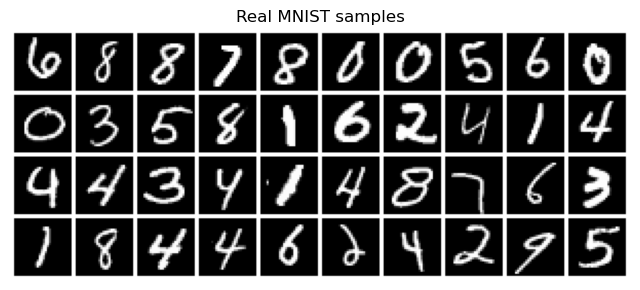

In [3]:
def show_grid(images, nrow=10, title=None, figsize=(8, 8)):
    # images: tensor (N, 1, 28, 28) with values in [0, 1]
    grid = torchvision.utils.make_grid(images.detach().cpu(), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=figsize)
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

x, y = next(iter(train_loader))
show_grid(x[:40], title="Real MNIST samples", figsize=(8, 3.5))

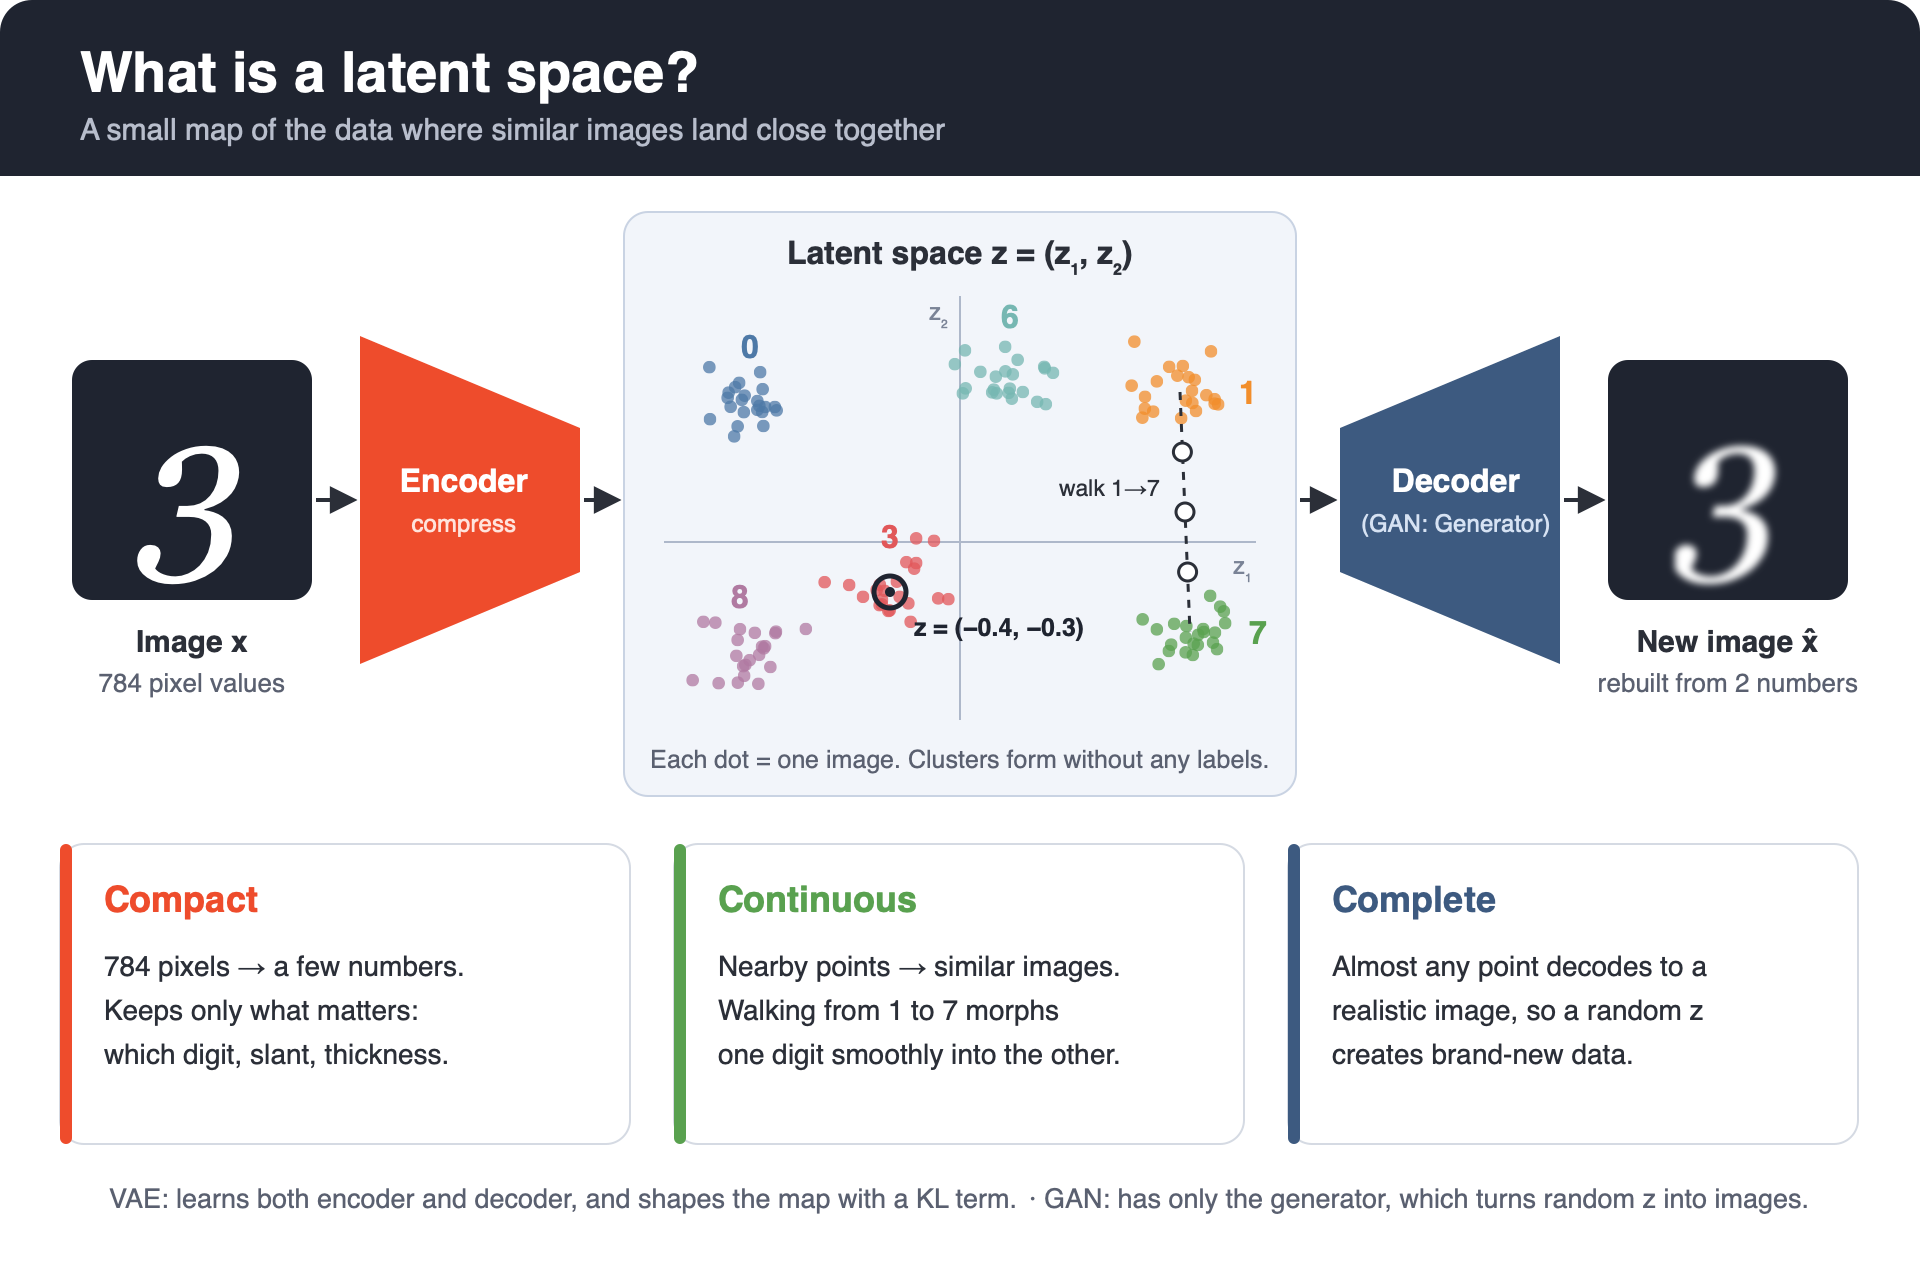

## Part 1 — What is a latent space?

An MNIST image has $28 \times 28 = 784$ pixels, so each image is a point in $\mathbb{R}^{784}$.
But almost all points in $\mathbb{R}^{784}$ look like TV static — real digits occupy a tiny, curved, low-dimensional region
(the **manifold hypothesis**).

A **latent space** is a compact coordinate system $\mathbf{z} \in \mathbb{R}^d$ (with $d \ll 784$) for that region:

$$
\underbrace{\mathbf{x} \in \mathbb{R}^{784}}_{\text{data space}}
\;\xrightarrow{\text{encoder}}\;
\underbrace{\mathbf{z} \in \mathbb{R}^{d}}_{\text{latent space}}
\;\xrightarrow{\text{decoder / generator}}\;
\hat{\mathbf{x}} \in \mathbb{R}^{784}
$$

A *good* latent space has three properties:

| Property | Meaning | Why it matters |
|---|---|---|
| **Compact** | $d$ is small | Captures the essential *factors of variation* (digit identity, slant, stroke width…) |
| **Continuous** | nearby $\mathbf{z}$ ⇒ similar images | Interpolation produces smooth, meaningful transitions |
| **Complete** | (almost) every $\mathbf{z}$ decodes to a realistic image | We can **sample** new data by picking random $\mathbf{z}$ |

> A plain autoencoder gives you *compact* but not necessarily *continuous* or *complete*: it may scatter codes
> arbitrarily, leaving "holes" that decode to garbage. VAEs and GANs both fix this, in very different ways.

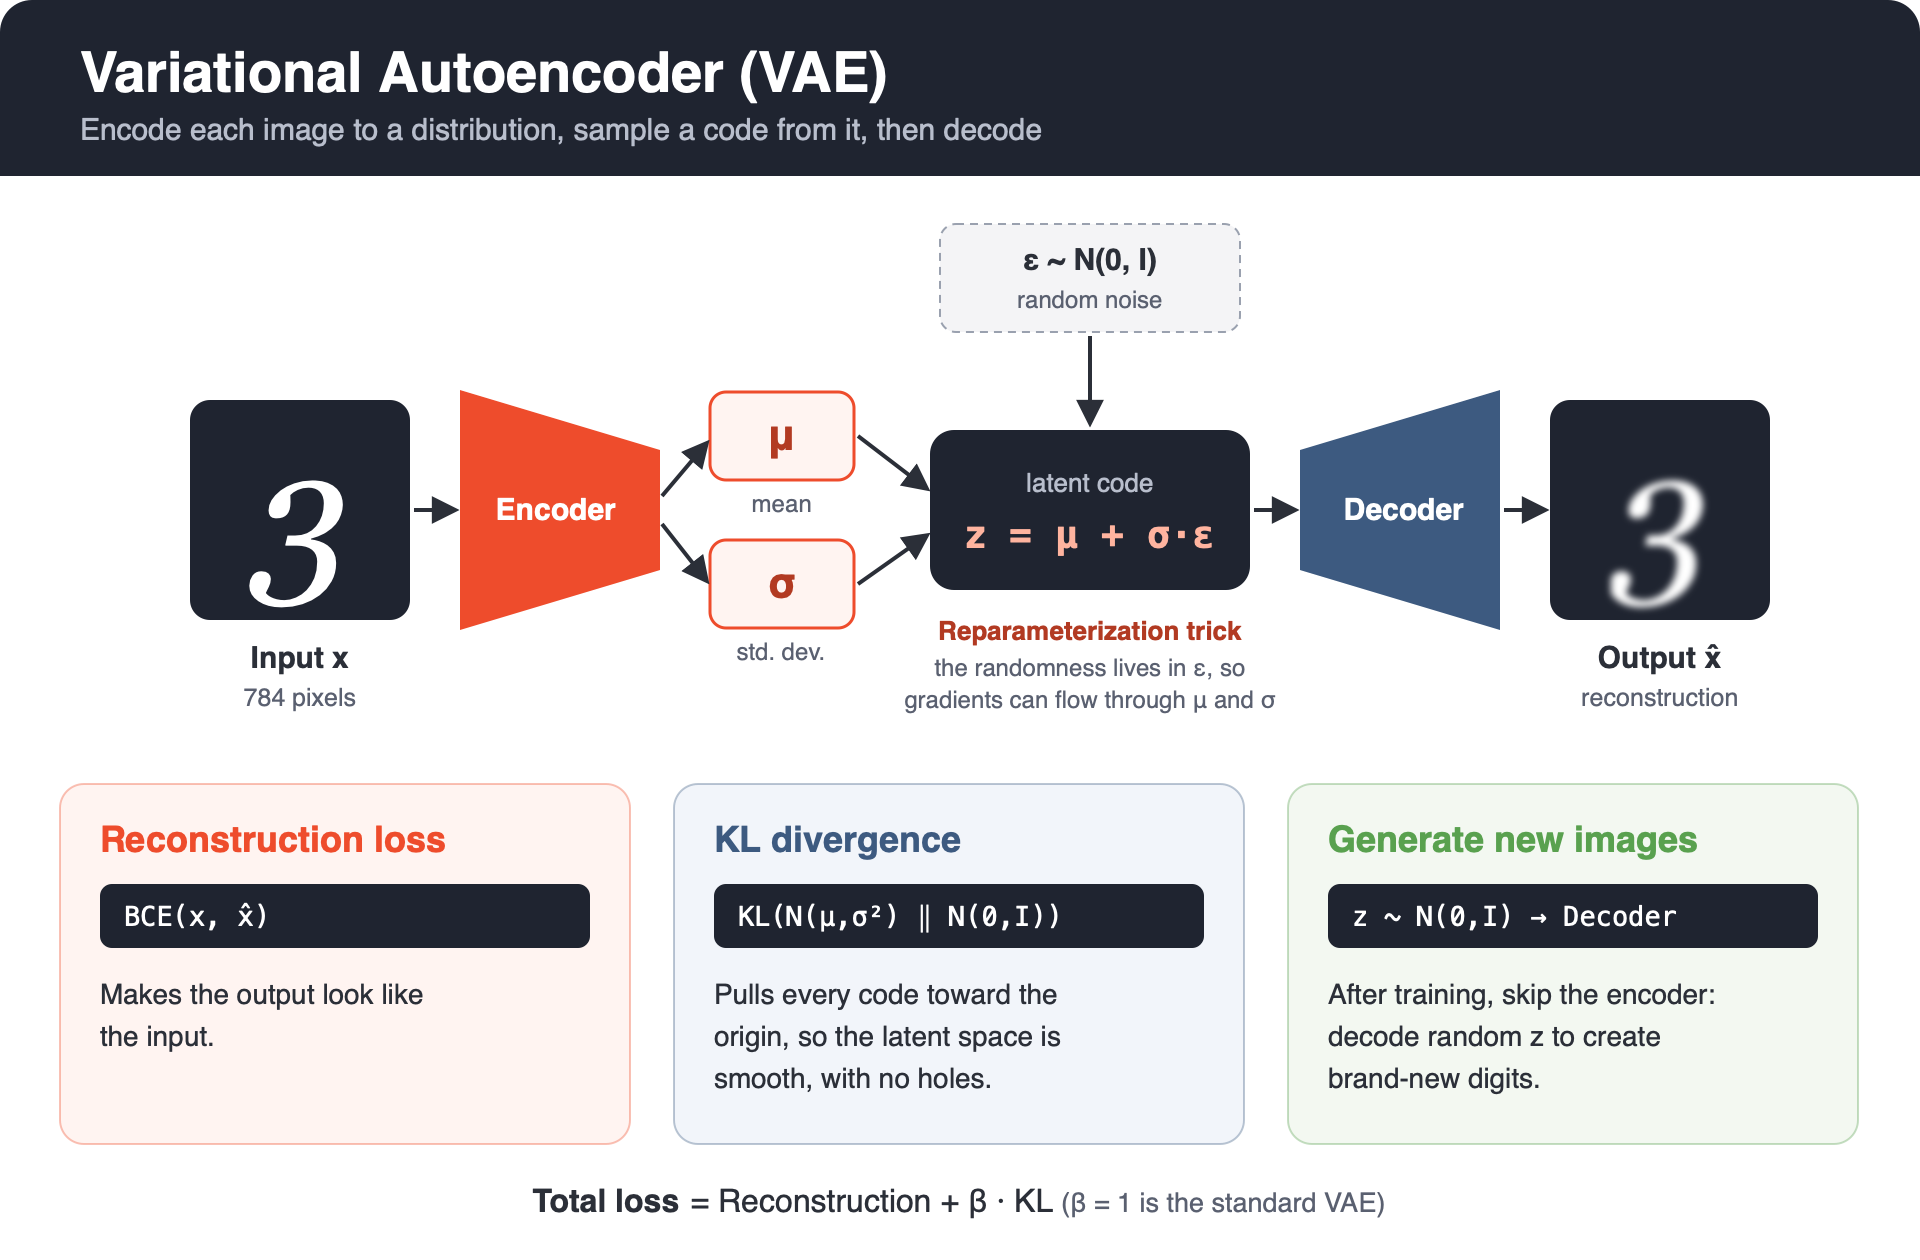

## Part 2 — Variational Autoencoders (VAE)

### 2.1 Idea
Instead of mapping $\mathbf{x}$ to a single point, the **encoder** outputs a *distribution* over latent codes:

$$ q_\phi(\mathbf{z}\mid\mathbf{x}) = \mathcal{N}\big(\boldsymbol{\mu}_\phi(\mathbf{x}),\ \operatorname{diag}(\boldsymbol{\sigma}^2_\phi(\mathbf{x}))\big) $$

The **decoder** $p_\theta(\mathbf{x}\mid\mathbf{z})$ reconstructs the image. We also choose a simple **prior** $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, I)$.

### 2.2 The objective (ELBO)
We maximize the **Evidence Lower BOund** on $\log p_\theta(\mathbf{x})$; equivalently, we minimize

$$
\mathcal{L}(\mathbf{x}) =
\underbrace{-\,\mathbb{E}_{q_\phi(\mathbf{z}\mid\mathbf{x})}\big[\log p_\theta(\mathbf{x}\mid\mathbf{z})\big]}_{\text{reconstruction loss}}
\; + \;
\beta\,\underbrace{D_{\mathrm{KL}}\big(q_\phi(\mathbf{z}\mid\mathbf{x})\,\|\,p(\mathbf{z})\big)}_{\text{regularizer}}
\qquad(\beta = 1 \text{ for the standard VAE})
$$

* **Reconstruction** pushes codes to be *informative* (binary cross-entropy for pixel values in $[0,1]$).
* **KL** pushes every $q(\mathbf{z}\mid\mathbf{x})$ toward $\mathcal{N}(0, I)$, which packs the codes together around the origin and
  removes holes ⇒ the latent space becomes **continuous and complete**.

For diagonal Gaussians the KL has a closed form:

$$ D_{\mathrm{KL}} = -\tfrac{1}{2}\sum_{j=1}^{d}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right) $$

### 2.3 The reparameterization trick
Sampling $\mathbf{z}\sim\mathcal{N}(\boldsymbol\mu, \boldsymbol\sigma^2)$ is not differentiable w.r.t. $\boldsymbol\mu, \boldsymbol\sigma$.
Rewrite the sample as a deterministic function of the parameters plus independent noise:

$$ \mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\epsilon}, \qquad \boldsymbol{\epsilon}\sim\mathcal{N}(\mathbf{0}, I) $$

Now gradients flow through $\boldsymbol\mu$ and $\boldsymbol\sigma$. We predict $\log\sigma^2$ (called `logvar`) for numerical stability.

In [4]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2, hidden=512):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, hidden), nn.ReLU(),
            nn.Linear(hidden, 256), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, hidden), nn.ReLU(),
            nn.Linear(hidden, 784),          # logits; apply sigmoid to get pixels
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)  # logits

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss(logits, x, mu, logvar, beta=1.0):
    # Both terms are summed over pixels / latent dims and averaged over the batch.
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + beta * kl, recon, kl

### 2.4 Train a VAE with a **2-D** latent space
We deliberately use $d = 2$ so we can *look at* the whole latent space. (Larger $d$ gives sharper reconstructions — you'll explore that in the assignment.)

In [ ]:
VAE_EPOCHS = 15  # ~1-2 min on a GPU; lower this on CPU

vae = VAE(latent_dim=2).to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_history = []

for epoch in range(1, VAE_EPOCHS + 1):
    vae.train()
    t0, tot, rec, kld = time.time(), 0.0, 0.0, 0.0
    for x, _ in train_loader:
        x = x.to(device)
        logits, mu, logvar = vae(x)
        loss, r, k = vae_loss(logits, x, mu, logvar)
        opt.zero_grad()
        loss.backward()
        opt.step()
        tot, rec, kld = tot + loss.item(), rec + r.item(), kld + k.item()
    n = len(train_loader)
    vae_history.append((tot / n, rec / n, kld / n))
    print(f"epoch {epoch:2d} | loss {tot/n:7.2f} | recon {rec/n:7.2f} | KL {kld/n:5.2f} | {time.time()-t0:4.1f}s")

epoch  1 | loss  183.36 | recon  179.34 | KL  4.01 |  8.3s
epoch  2 | loss  161.24 | recon  155.92 | KL  5.32 |  7.7s
epoch  3 | loss  155.05 | recon  149.33 | KL  5.72 |  7.7s
epoch  4 | loss  151.86 | recon  145.96 | KL  5.90 |  7.7s
epoch  5 | loss  149.30 | recon  143.21 | KL  6.09 |  7.7s
epoch  6 | loss  147.80 | recon  141.62 | KL  6.18 |  7.8s
epoch  7 | loss  146.54 | recon  140.26 | KL  6.28 |  7.7s
epoch  8 | loss  145.86 | recon  139.53 | KL  6.33 |  7.8s


In [ ]:
h = np.array(vae_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 1], label="reconstruction"); ax[0].set_title("Reconstruction loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 2], color="tab:orange"); ax[1].set_title("KL divergence"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

# Reconstructions: top row = originals, bottom row = VAE outputs
vae.eval()
with torch.no_grad():
    x, _ = next(iter(test_loader))
    x = x[:10].to(device)
    mu, _ = vae.encode(x)
    recon = torch.sigmoid(vae.decode(mu))
show_grid(torch.cat([x, recon]), nrow=10, title="Top: original | Bottom: reconstruction (d=2)", figsize=(10, 2.5))

## Part 3 — Exploring the VAE latent space

### 3.1 Where does each digit live?
Encode the whole test set and plot $\boldsymbol\mu(\mathbf{x})$, coloured by the true label.
**The VAE never saw the labels** — any clustering you see was discovered on its own.

In [ ]:
@torch.no_grad()
def encode_dataset(model, loader):
    model.eval()
    zs, ys = [], []
    for x, y in loader:
        mu, _ = model.encode(x.to(device))
        zs.append(mu.cpu()); ys.append(y)
    return torch.cat(zs), torch.cat(ys)

Z, Y = encode_dataset(vae, test_loader)

plt.figure(figsize=(7, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=Y, cmap="tab10", s=3, alpha=0.7)
plt.colorbar(sc, ticks=range(10), label="digit")
plt.xlabel("$z_1$"); plt.ylabel("$z_2$")
plt.title("VAE latent space (test set means)")
plt.gca().set_aspect("equal")
plt.show()

**Discuss:**
* Which digits overlap? Why might 4 and 9 (or 3, 5, 8) be neighbours?
* Notice the codes are packed roughly inside a disc around the origin — that's the KL term pulling toward $\mathcal{N}(0, I)$.

### 3.2 The learned manifold
Because the latent space is *complete*, we can decode a regular grid of $\mathbf{z}$ values — even points that no training image mapped to.

In [ ]:
@torch.no_grad()
def plot_manifold(model, n=20, lim=2.5):
    model.eval()
    grid = torch.linspace(-lim, lim, n)
    zz = torch.stack(torch.meshgrid(grid, grid.flip(0), indexing="xy"), dim=-1).reshape(-1, 2)
    imgs = torch.sigmoid(model.decode(zz.to(device)))
    show_grid(imgs, nrow=n, title=f"Decoded grid over $z \\in [-{lim}, {lim}]^2$", figsize=(9, 9))

plot_manifold(vae)

### 3.3 Interpolation
Take two real images, encode them to $\mathbf{z}_a$ and $\mathbf{z}_b$, and walk the straight line between them:

$$ \mathbf{z}(t) = (1-t)\,\mathbf{z}_a + t\,\mathbf{z}_b, \qquad t\in[0,1] $$

In a continuous latent space every intermediate step should look like a plausible digit.

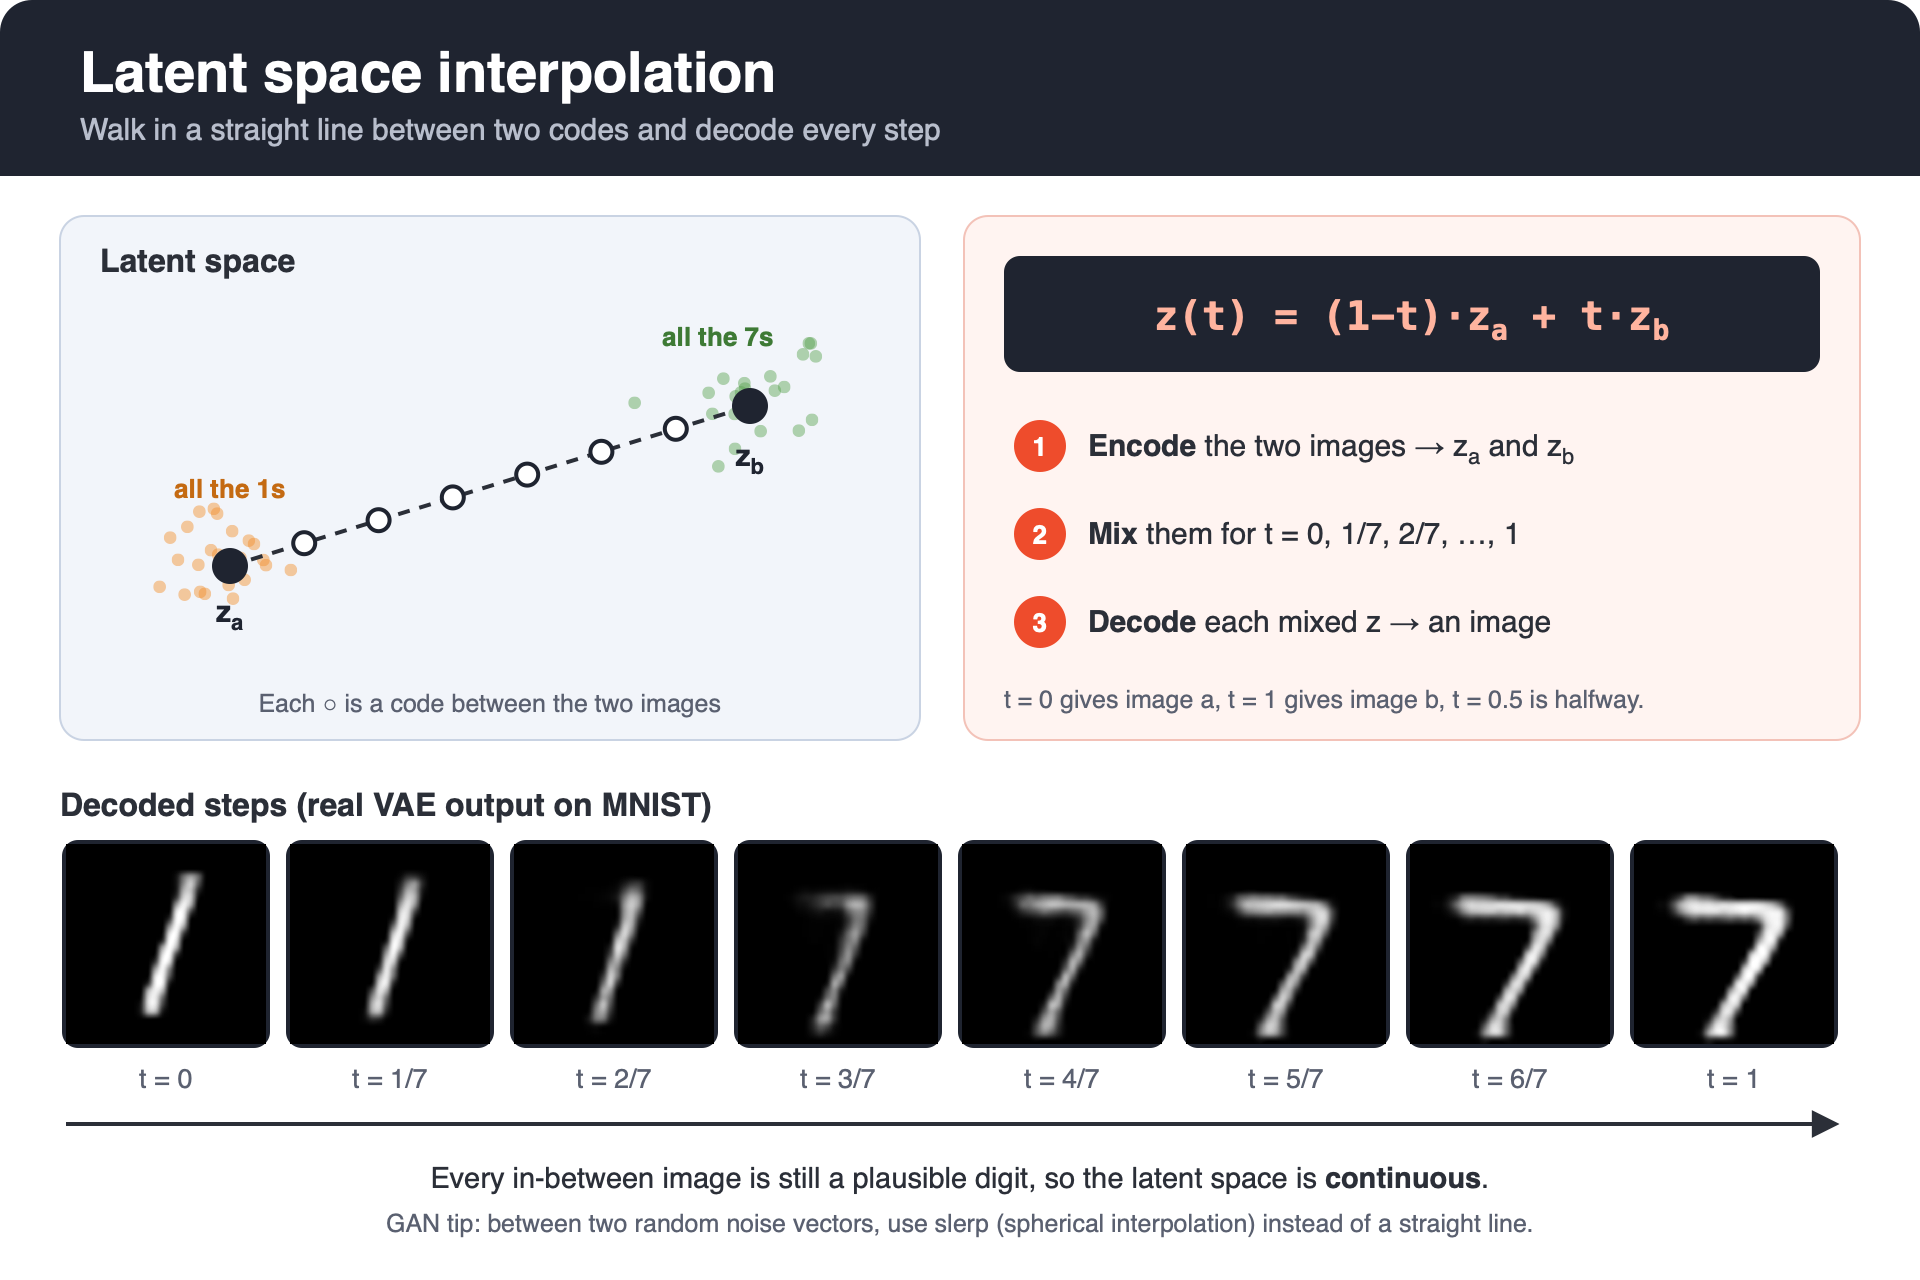

In [ ]:
@torch.no_grad()
def vae_interpolate(model, xa, xb, steps=10):
    model.eval()
    za, _ = model.encode(xa.unsqueeze(0).to(device))
    zb, _ = model.encode(xb.unsqueeze(0).to(device))
    t = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    z = (1 - t) * za + t * zb
    return torch.sigmoid(model.decode(z))

def first_index_of(label, ds=test_ds):
    return next(i for i in range(len(ds)) if ds[i][1] == label)

pairs = [(1, 7), (3, 8), (4, 9), (0, 6)]
rows = [vae_interpolate(vae, test_ds[first_index_of(a)][0], test_ds[first_index_of(b)][0]) for a, b in pairs]
show_grid(torch.cat(rows), nrow=10, title="VAE interpolations: " + ", ".join(f"{a}→{b}" for a, b in pairs), figsize=(10, 4.5))

### 3.4 Sampling brand-new digits
Sample $\mathbf{z}\sim\mathcal{N}(0, I)$ from the prior and decode. This is what makes the VAE a **generative** model.

In [ ]:
with torch.no_grad():
    z = torch.randn(50, vae.latent_dim, device=device)
    samples = torch.sigmoid(vae.decode(z))
show_grid(samples, nrow=10, title="VAE samples from the prior", figsize=(8, 4.5))

**Observation:** VAE samples are recognisable but **blurry**. The pixel-wise reconstruction loss rewards the decoder for predicting the
*average* of all plausible images when it is uncertain. GANs attack exactly this weakness.

---
## Part 4 — Generative Adversarial Networks (GAN)

### 4.1 Idea: a two-player game
* **Generator** $G(\mathbf{z})$: maps noise $\mathbf{z}\sim p(\mathbf{z})$ to a fake image. It never sees real data directly.
* **Discriminator** $D(\mathbf{x})$: outputs the probability that $\mathbf{x}$ is real.

$$
\min_G \max_D \; V(D, G) =
\mathbb{E}_{\mathbf{x}\sim p_\text{data}}\big[\log D(\mathbf{x})\big] +
\mathbb{E}_{\mathbf{z}\sim p(\mathbf{z})}\big[\log\big(1 - D(G(\mathbf{z}))\big)\big]
$$

At the theoretical optimum $p_G = p_\text{data}$ and $D(\mathbf{x}) = \tfrac12$ everywhere.

### 4.2 Training in practice
Alternate two steps on every mini-batch:
1. **Discriminator step:** minimise $\;\text{BCE}(D(\mathbf{x}_\text{real}), 1) + \text{BCE}(D(G(\mathbf{z})), 0)$ (with $G$ frozen — note the `.detach()`).
2. **Generator step:** minimise $\;\text{BCE}(D(G(\mathbf{z})), 1)$.
   This is the **non-saturating** loss: instead of minimising $\log(1-D(G(z)))$ (whose gradient vanishes when $D$ easily rejects fakes early on), we maximise $\log D(G(z))$.

### 4.3 What does the GAN latent space look like?
* There is **no encoder**: $\mathbf{z}$ is pure input noise, and $G$ *learns* to give it meaning.
* There is **no KL term**; continuity comes only implicitly from $G$ being a smooth neural network.
* Common failure: **mode collapse** — $G$ maps many different $\mathbf{z}$ to the same few outputs (e.g. only 1s and 7s).

> Data is rescaled to $[-1, 1]$ for the GAN because the generator ends with `tanh`.

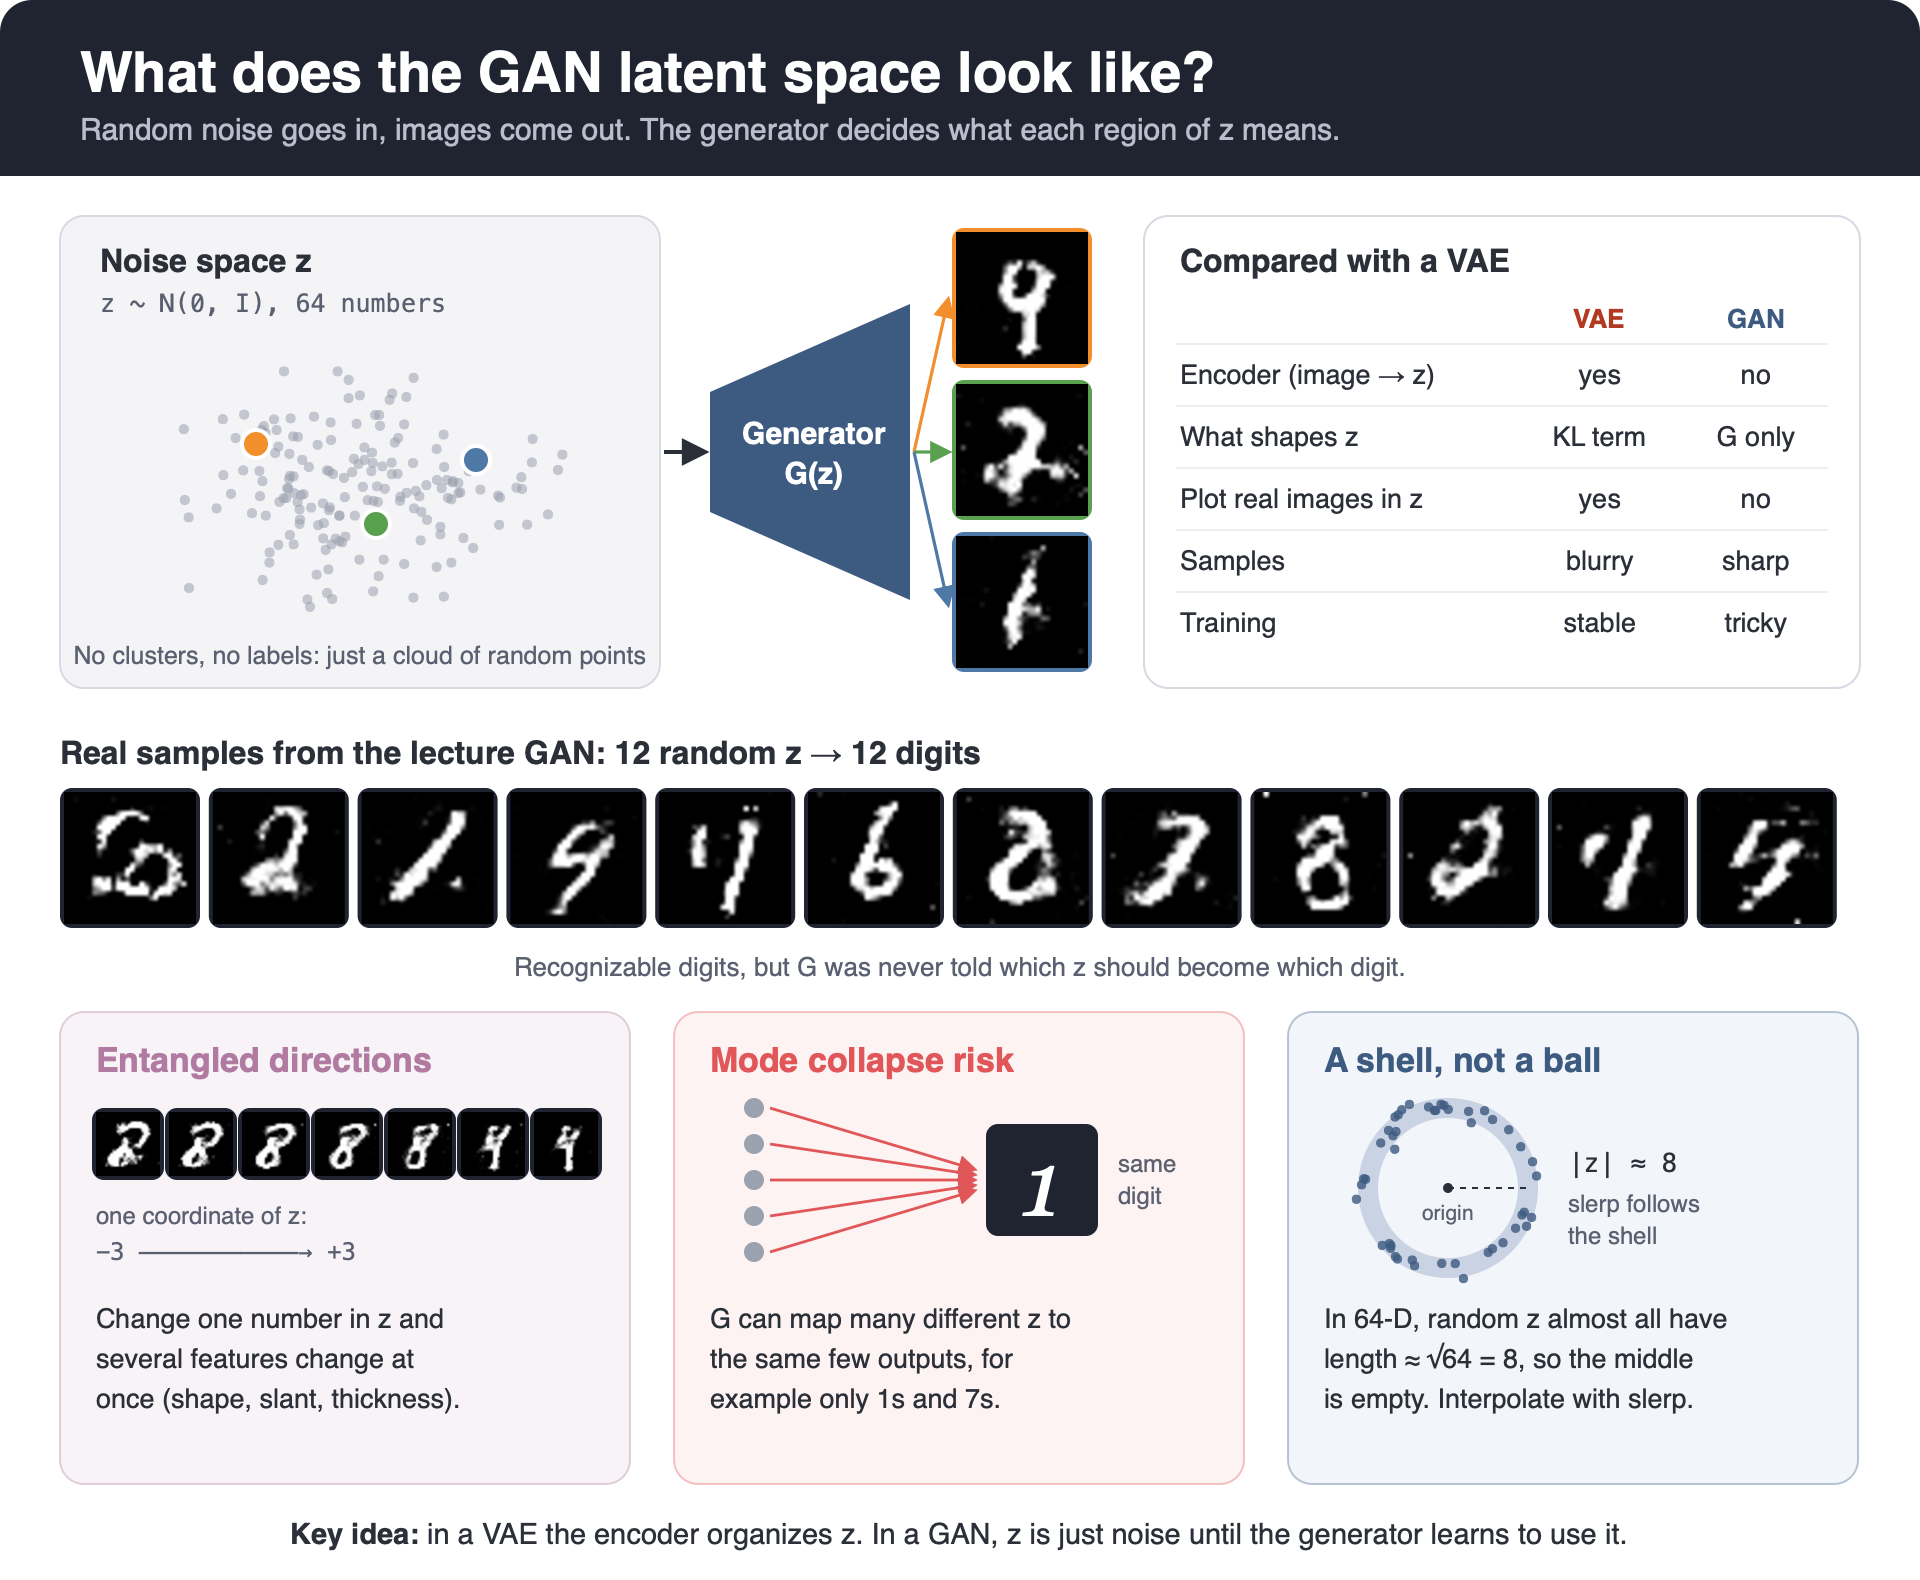

In [ ]:
Z_DIM = 64

class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.BatchNorm1d(1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1),  # logit; BCEWithLogits applies the sigmoid
        )

    def forward(self, x):
        return self.net(x)


G, D = Generator().to(device), Discriminator().to(device)
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

to_gan = lambda x: x * 2 - 1          # [0,1]  -> [-1,1]
from_gan = lambda x: (x + 1) / 2      # [-1,1] -> [0,1]
print(f"G params: {sum(p.numel() for p in G.parameters()):,} | D params: {sum(p.numel() for p in D.parameters()):,}")

In [ ]:
GAN_EPOCHS = 30  # ~3-4 min on a GPU; GANs need more epochs than VAEs

fixed_z = torch.randn(40, Z_DIM, device=device)   # same noise every time -> watch learning progress
gan_history, snapshots = [], {}

for epoch in range(1, GAN_EPOCHS + 1):
    G.train(); D.train()
    t0, d_sum, g_sum = time.time(), 0.0, 0.0
    for x, _ in train_loader:
        real = to_gan(x.to(device))
        b = real.size(0)
        ones, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)

        # ---- 1) Discriminator step ----
        fake = G(torch.randn(b, Z_DIM, device=device))
        d_loss = bce(D(real), ones) + bce(D(fake.detach()), zeros)
        opt_D.zero_grad(); d_loss.backward(); opt_D.step()

        # ---- 2) Generator step (non-saturating) ----
        g_loss = bce(D(fake), ones)
        opt_G.zero_grad(); g_loss.backward(); opt_G.step()

        d_sum += d_loss.item(); g_sum += g_loss.item()
    n = len(train_loader)
    gan_history.append((d_sum / n, g_sum / n))
    if epoch in (1, 5, GAN_EPOCHS // 2, GAN_EPOCHS):
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = from_gan(G(fixed_z)).cpu()
    print(f"epoch {epoch:2d} | D loss {d_sum/n:.3f} | G loss {g_sum/n:.3f} | {time.time()-t0:4.1f}s")

In [ ]:
h = np.array(gan_history)
plt.figure(figsize=(7, 3.5))
plt.plot(h[:, 0], label="Discriminator"); plt.plot(h[:, 1], label="Generator")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("GAN losses (they don't simply go down!)")
plt.show()

for ep, imgs in snapshots.items():
    show_grid(imgs, nrow=10, title=f"Generator output on fixed noise — epoch {ep}", figsize=(8, 3.5))

**Discuss:** Unlike the VAE, GAN losses do **not** steadily decrease — the two players are competing, so the loss is not a direct measure of sample quality.
Inspect the images instead.

## Part 5 — Exploring the GAN latent space

### 5.1 Interpolation in noise space
We can't encode real images (no encoder!), so we interpolate between two *random* noise vectors.
For high-dimensional Gaussians, **spherical interpolation (slerp)** is often preferred: linear interpolation passes close to the origin,
where the prior has very little mass in high dimensions (most samples have norm $\approx\sqrt{d}$).

In [ ]:
def lerp(a, b, t):
    return (1 - t) * a + t * b

def slerp(a, b, t):
    a_n, b_n = a / a.norm(dim=-1, keepdim=True), b / b.norm(dim=-1, keepdim=True)
    omega = torch.acos((a_n * b_n).sum(-1, keepdim=True).clamp(-1, 1))
    so = torch.sin(omega)
    return (torch.sin((1 - t) * omega) / so) * a + (torch.sin(t * omega) / so) * b

@torch.no_grad()
def gan_interpolate(G, za, zb, steps=10, mode="slerp"):
    G.eval()
    t = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    z = slerp(za, zb, t) if mode == "slerp" else lerp(za, zb, t)
    return from_gan(G(z))

torch.manual_seed(3)
rows = []
for _ in range(4):
    za, zb = torch.randn(1, Z_DIM, device=device), torch.randn(1, Z_DIM, device=device)
    rows.append(gan_interpolate(G, za, zb))
show_grid(torch.cat(rows), nrow=10, title="GAN interpolations between random z (slerp)", figsize=(10, 4.5))
print("norm of a typical z:", torch.randn(10000, Z_DIM).norm(dim=1).mean().item(), "≈ sqrt(d) =", Z_DIM ** 0.5)

### 5.2 Walking along a single latent direction
Hold $\mathbf{z}$ fixed and vary one coordinate. In a GAN, individual coordinates are usually **entangled** — one coordinate may change several attributes at once.

In [ ]:
@torch.no_grad()
def latent_walk(G, dims=(0, 1, 2, 3), span=3.0, steps=10, seed=0):
    G.eval()
    g = torch.Generator(device="cpu").manual_seed(seed)
    base = torch.randn(1, Z_DIM, generator=g).to(device)
    rows = []
    for d in dims:
        z = base.repeat(steps, 1)
        z[:, d] = torch.linspace(-span, span, steps, device=device)
        rows.append(from_gan(G(z)))
    return torch.cat(rows)

show_grid(latent_walk(G), nrow=10, title="Varying z[0], z[1], z[2], z[3] (one per row)", figsize=(10, 4.5))

In [ ]:
with torch.no_grad():
    G.eval()
    gan_samples = from_gan(G(torch.randn(50, Z_DIM, device=device)))
    vae_samples = torch.sigmoid(vae.decode(torch.randn(50, vae.latent_dim, device=device)))
show_grid(vae_samples, nrow=10, title="VAE samples (d=2)", figsize=(8, 4.5))
show_grid(gan_samples, nrow=10, title=f"GAN samples (d={Z_DIM})", figsize=(8, 4.5))

## Part 6 — VAE vs. GAN

| | **VAE** | **GAN** |
|---|---|---|
| Training signal | Reconstruction + KL (a likelihood bound) | Adversarial feedback from a discriminator |
| Encoder $\mathbf{x}\to\mathbf{z}$? | ✅ Yes | ❌ No (needs extra work, e.g. GAN inversion / BiGAN) |
| Latent structure | Explicitly regularised toward $\mathcal{N}(0,I)$; smooth & complete | Implicit; defined by what $G$ learns |
| Sample sharpness | Blurry (averaging effect) | Sharp |
| Mode coverage | Good — every training point must be reconstructed | Risk of **mode collapse** |
| Training stability | Stable, loss is meaningful | Unstable, loss is hard to interpret |
| Typical uses | Representation learning, anomaly detection, latent spaces for diffusion (Stable Diffusion's VAE!) | High-fidelity image synthesis, super-resolution, style transfer |

### Key takeaways
1. A latent space is a **learned coordinate system** for the data manifold.
2. VAEs *shape* the latent space explicitly via the KL term — great for **navigating** and **encoding**.
3. GANs *learn to use* a fixed noise distribution — great for **sharp samples**, but harder to train and inspect.
4. Modern systems often **combine** ideas: VQ-GAN, VAE-GAN, and latent diffusion all use a VAE/GAN-style latent space.

### Discussion questions
1. What would happen to the VAE's latent space if we set $\beta = 0$? What about a very large $\beta$?
2. Why can't we just compute the GAN's likelihood $p_G(\mathbf{x})$ and maximise it?
3. If you wanted to edit a *real* photo (e.g. make a face smile) using a GAN, what extra component would you need?
4. Why does the VAE latent plot look like a disc, and why might that be both helpful and limiting?

➡️ **Next:** open `02_Assignment_Latent_Space.ipynb`.